# Optimization: GD, SGD, Momentum, Adam

**Goal:** Implement optimization algorithms from scratch and compare them on a real loss surface.

**Reference:** Mathematics for ML - Chapter 7

## The Optimization Problem

We want to find:

$$\theta^* = \arg\min_\theta f(\theta)$$

where $f$ is a **loss function** and $\theta$ are the **model parameters**.

**Challenges:**
- $f$ is usually **non-convex** (many local minima, saddle points)
- Dimension $d$ can be millions (neural nets)
- We don't have access to the full gradient — only mini-batch estimates

**The core update:**
$$\theta_{t+1} = \theta_t - \eta \cdot g_t$$

where $g_t$ is the gradient direction and $\eta$ is the learning rate.

In [15]:
import numpy as np
import matplotlib.pyplot as plt

## Vanilla Gradient Descent

**Update:**
$$\theta_{t+1} = \theta_t - \eta \nabla f(\theta_t)$$

**Pros:** simple, converges for convex problems
**Cons:** 
- Slow in ravines (long narrow valleys)
- Same learning rate for all parameters
- Sensitive to scale of features

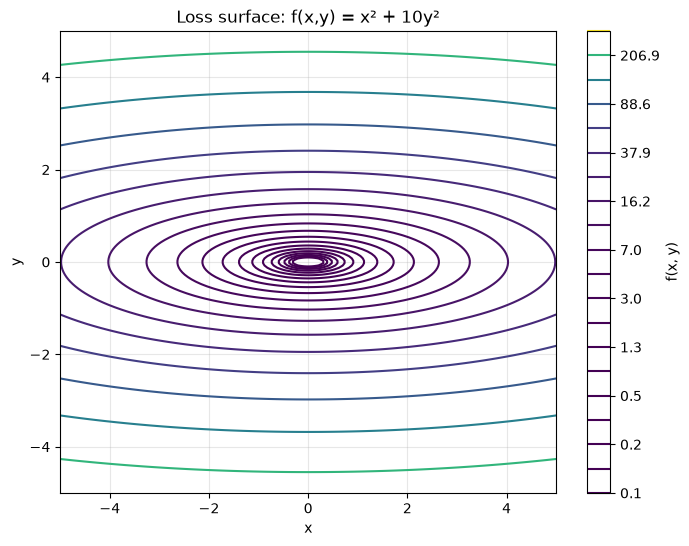

In [16]:
# A challenging 2D loss: elongated valley (ill-conditioned)
def f(x):
    """Rosenbrock-like valley function."""
    return x[0]**2 + 10 * x[1]**2


def grad_f(x):
    """Analytical gradient."""
    return np.array([2 * x[0], 20 * x[1]])


# Visualize
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(x, y)
Z = X**2 + 10 * Y**2

plt.figure(figsize=(8, 6))
plt.contour(X, Y, Z, levels=np.logspace(-1, 2.5, 20), cmap='viridis')
plt.colorbar(label='f(x, y)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Loss surface: f(x,y) = x² + 10y²')
plt.grid(True, alpha=0.3)
plt.show()

In [17]:
def gradient_descent(grad_f, x0, lr=0.01, n_steps=100):
    """Standard gradient descent."""
    x = np.array(x0, dtype=float)
    history = [x.copy()]
    for _ in range(n_steps):
        g = grad_f(x)
        x = x - lr * g
        history.append(x.copy())
    return np.array(history)


history_gd = gradient_descent(grad_f, x0=[4.0, 4.0], lr=0.01, n_steps=200)
print(f"GD final: {history_gd[-1]}, f = {f(history_gd[-1]):.6e}")
print(f"Steps to reach |x| < 0.1: ", np.argmax(np.linalg.norm(history_gd, axis=1) < 0.1))

GD final: [7.03517864e-02 1.65980623e-19], f = 4.949374e-03
Steps to reach |x| < 0.1:  183


## Stochastic Gradient Descent (SGD)

Instead of computing the full gradient over all $N$ data points, use a **mini-batch** of size $B$:

$$\theta_{t+1} = \theta_t - \eta \nabla f_{B_t}(\theta_t)$$

**Advantages:**
- Much cheaper per step ($O(B)$ instead of $O(N)$)
- Noise helps escape saddle points
- Works with streaming data

**Disadvantages:**
- Noisy updates (doesn't converge exactly)
- Needs learning rate schedule (decay over time)

**In practice:** $B \in [32, 512]$ usually.

In [18]:
def sgd_sim(grad_f, x0, lr=0.01, n_steps=200, noise=0.5):
    """
    Simulated SGD: same as GD but with noise added to the gradient.
    In real ML, noise comes from mini-batch sampling.
    """
    x = np.array(x0, dtype=float)
    history = [x.copy()]
    for _ in range(n_steps):
        g = grad_f(x) + noise * np.random.randn(2)
        x = x - lr * g
        history.append(x.copy())
    return np.array(history)


np.random.seed(0)
history_sgd = sgd_sim(grad_f, x0=[4.0, 4.0], lr=0.01, n_steps=200)
print(f"SGD final: {history_sgd[-1]}, f = {f(history_sgd[-1]):.6e}")

SGD final: [0.09881014 0.00278127], f = 9.840799e-03


## Momentum

Add a **velocity** term that accumulates past gradients:

$$v_t = \beta v_{t-1} + \nabla f(\theta_t)$$
$$\theta_{t+1} = \theta_t - \eta v_t$$

where $\beta \in [0, 1)$ is the momentum coefficient (typically 0.9).

**Intuition:** like a ball rolling downhill — it builds up speed in consistent directions and dampens oscillations.

**Why it helps:**
- Faster convergence in ravines
- Smooths out noisy gradients (SGD + momentum is standard)
- Escapes shallow local minima

In [19]:
def momentum(grad_f, x0, lr=0.01, beta=0.9, n_steps=200):
    """Gradient descent with momentum."""
    x = np.array(x0, dtype=float)
    v = np.zeros_like(x)
    history = [x.copy()]
    for _ in range(n_steps):
        g = grad_f(x)
        v = beta * v + g
        x = x - lr * v
        history.append(x.copy())
    return np.array(history)


history_mom = momentum(grad_f, x0=[4.0, 4.0], lr=0.01, beta=0.9, n_steps=200)
print(f"Momentum final: {history_mom[-1]}, f = {f(history_mom[-1]):.6e}")

Momentum final: [-8.26613969e-06 -5.36812706e-05], f = 2.888512e-08


## Adam (Adaptive Moment Estimation)

Adam combines **momentum** with **adaptive learning rates per parameter**:

$$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t \quad \text{(first moment)}$$
$$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2 \quad \text{(second moment)}$$

**Bias correction** (important for early steps):
$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \quad \hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$

**Update:**
$$\theta_{t+1} = \theta_t - \eta \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$$

**Default hyperparameters:**
- $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$
- $\eta = 10^{-3}$

**Why it works:**
- $m_t$ smooths the gradient (momentum)
- $v_t$ scales per-parameter (adaptive)
- Parameters with small gradients get larger updates

**The default optimizer for most deep learning in 2024.**

In [20]:
def adam(grad_f, x0, lr=0.1, beta1=0.9, beta2=0.999, eps=1e-8, n_steps=200):
    """Adam optimizer."""
    x = np.array(x0, dtype=float)
    m = np.zeros_like(x)
    v = np.zeros_like(x)
    history = [x.copy()]
    for t in range(1, n_steps + 1):
        g = grad_f(x)
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g**2
        m_hat = m / (1 - beta1**t)
        v_hat = v / (1 - beta2**t)
        x = x - lr * m_hat / (np.sqrt(v_hat) + eps)
        history.append(x.copy())
    return np.array(history)


history_adam = adam(grad_f, x0=[4.0, 4.0], lr=0.1, n_steps=200)
print(f"Adam final: {history_adam[-1]}, f = {f(history_adam[-1]):.6e}")

Adam final: [0.00013367 0.00013367], f = 1.965417e-07


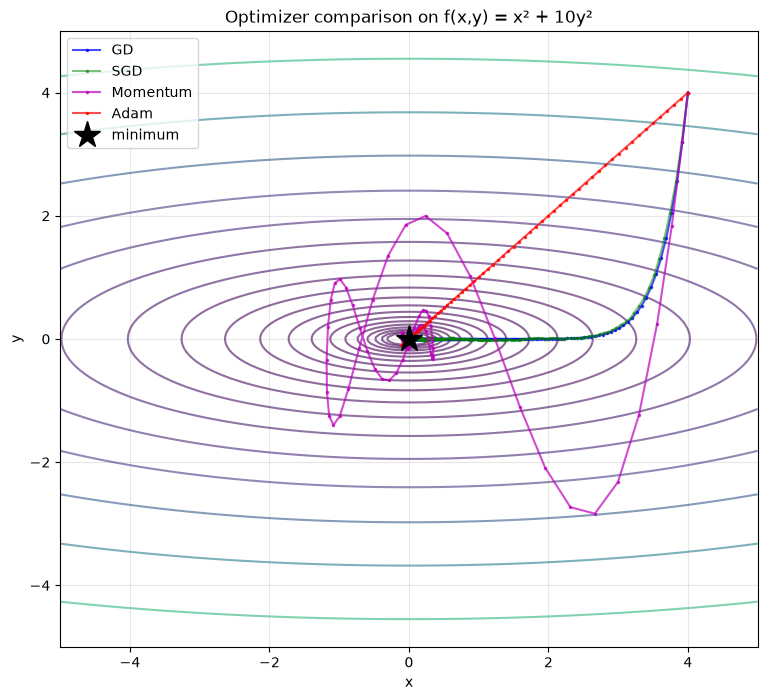

In [21]:
fig, ax = plt.subplots(figsize=(9, 8))

# Loss surface
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(x, y)
Z = X**2 + 10 * Y**2
ax.contour(X, Y, Z, levels=np.logspace(-1, 2.5, 20), cmap='viridis', alpha=0.6)

# Plot optimizer paths
ax.plot(history_gd[:, 0],    history_gd[:, 1],    'b.-', label='GD',        markersize=3, alpha=0.7)
ax.plot(history_sgd[:, 0],   history_sgd[:, 1],   'g.-', label='SGD',       markersize=3, alpha=0.5)
ax.plot(history_mom[:, 0],   history_mom[:, 1],   'm.-', label='Momentum',  markersize=3, alpha=0.7)
ax.plot(history_adam[:, 0],  history_adam[:, 1],  'r.-', label='Adam',      markersize=3, alpha=0.7)
ax.plot(0, 0, 'k*', markersize=20, label='minimum')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Optimizer comparison on f(x,y) = x² + 10y²')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## Summary

| Optimizer | Update | Adaptive | Memory |
|-----------|--------|----------|--------|
| GD | $-\eta g$ | No | 0 |
| SGD | $-\eta g_B$ | No | 0 |
| Momentum | $-\eta v$ | No | $d$ |
| Adam | $-\eta \hat{m} / \sqrt{\hat{v}}$ | Yes | $2d$ |

**When to use:**
- **GD:** small datasets, convex problems
- **SGD + Momentum:** classical CV models (ResNet, etc.)
- **Adam:** Transformers, most modern deep learning
- **AdamW:** Adam + decoupled weight decay (better for LLMs)

**Rule of thumb:** start with Adam (lr=1e-3), if you need better final performance try SGD + momentum (lr=0.1 with schedule).